In [1]:
import pandas as pd
import numpy as np

In [2]:
path = "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance).parquet"

In [7]:
df = pd.read_parquet(path)

In [8]:
df.shape

(99418, 29)

In [10]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

model_df = df.dropna(
    subset=final_features + ["is_delayed"]
).copy()

print(model_df.shape)

(95960, 29)


In [11]:
model_df[final_features + ["delivery_delay_days"]].corr()["delivery_delay_days"].sort_values()

average_distance_km         -0.074836
total_freight_value         -0.049373
item_count                  -0.031629
max_payment_installments    -0.031446
total_price                 -0.013052
average_product_height_cm   -0.002282
total_product_weight_g       0.002354
average_product_length_cm    0.009671
delivery_delay_days          1.000000
Name: delivery_delay_days, dtype: float64

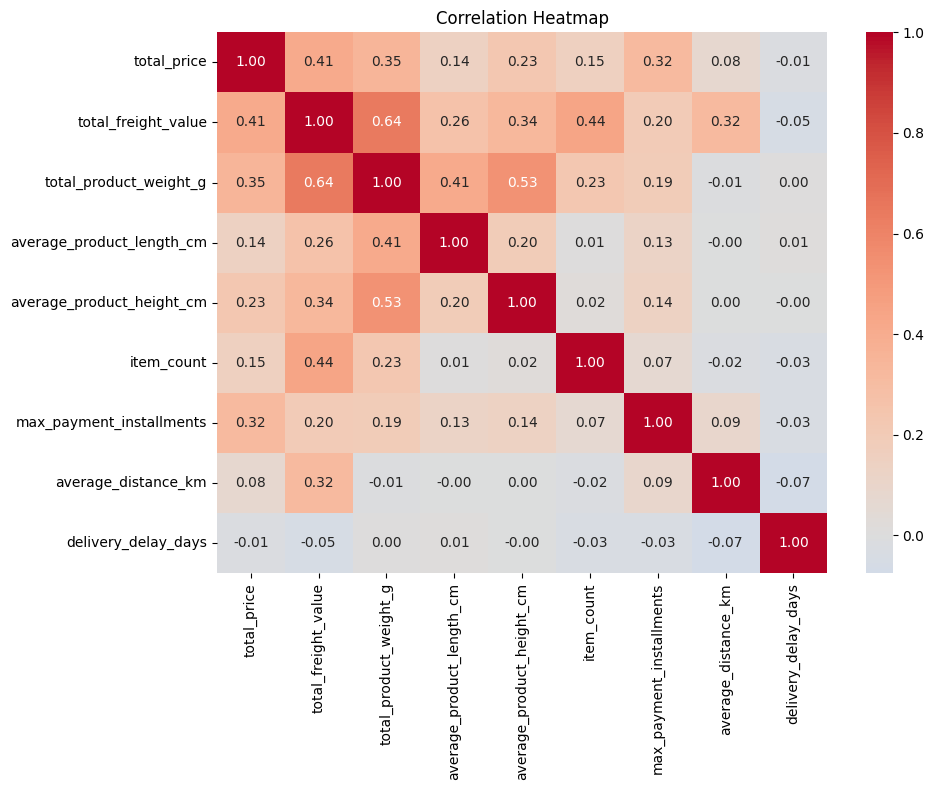

In [13]:
import seaborn as sns

import matplotlib.pyplot as plt

# Use only numeric modelling columns; exclude IDs, text, dates, and timedeltas
corr_columns = final_features + ["delivery_delay_days"]
corr = model_df[corr_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [15]:
df.corr()

ValueError: could not convert string to float: 'e481f51cbdc54678b7cc49136f2d6af7'

In [14]:
model_df[final_features].corr().round(3)

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,item_count,max_payment_installments,average_distance_km
total_price,1.000,0.411,0.351,0.145,0.228,0.154,0.316,0.080
total_freight_value,0.411,1.000,0.641,0.258,0.335,0.439,0.201,0.315
total_product_weight_g,0.351,0.641,1.000,0.412,0.531,0.230,0.192,-0.010
average_product_length_cm,0.145,0.258,0.412,1.000,0.197,0.008,0.126,-0.004
average_product_height_cm,0.228,0.335,0.531,0.197,1.000,0.018,0.138,0.000
item_count,0.154,0.439,0.230,0.008,0.018,1.000,0.067,-0.016
max_payment_installments,0.316,0.201,0.192,0.126,0.138,0.067,1.000,0.091
average_distance_km,0.080,0.315,-0.010,-0.004,0.000,-0.016,0.091,1.000
